# Previsão de alertas de dengue — definição epidemiológica

Esta é uma **segunda especificação**, mantida separada de `Notebook_Metodologicamente_Revisado.ipynb` e do notebook original. O objetivo é prever, com 4, 8, 12 e 16 semanas de antecedência:

1. o estado operacional de alerta exatamente em `t+h`;
2. o início de um novo episódio em qualquer semana de `t+1` a `t+h`.

O termo *alerta* é usado de forma deliberada. Um cruzamento do canal endêmico não equivale, sozinho, a uma declaração oficial de epidemia.

## Especificação pré-definida

- incidência = casos / população × 100.000;
- canal causal com somente anos anteriores;
- sete anos históricos, semanas epidemiológicas ±2 e mínimo de três anos;
- transformação `log1p`, centro geométrico e limite `média + 1,96 DP`;
- mobilização: acima da mediana e abaixo do limite por quatro semanas consecutivas;
- alerta: acima do limite superior por quatro semanas consecutivas;
- treino por data-alvo até 2021, validação 2022–2023 e teste 2024–2025.

Referências metodológicas: [Plano Nacional 2025](https://www.gov.br/saude/pt-br/centrais-de-conteudo/publicacoes/guias-e-manuais/2025/plano-de-contingencia-nacional-para-dengue-chikungunya-e-zika.pdf/@@download/file) e [diretrizes da OMS](https://tdr.who.int/docs/librariesprovider10/meeting-reports/dengue-diagnosis-pdf.pdf?download=true&sfvrsn=ef5ec264_0).

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image, Markdown

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / 'src/dengue_research').exists() else cwd.parent
OUTPUT_DIR = PROJECT_ROOT / 'outputs/revisao_epidemiologica'
REEXECUTE = False  # altere conscientemente para True para treinar tudo novamente

if REEXECUTE or not (OUTPUT_DIR / 'resultados_completos.json').exists():
    subprocess.run([sys.executable, str(PROJECT_ROOT / 'scripts/run_epidemiological_study.py')], cwd=PROJECT_ROOT, check=True)

results = json.loads((OUTPUT_DIR / 'resultados_completos.json').read_text(encoding='utf-8'))
metrics = pd.read_csv(OUTPUT_DIR / 'metricas_consolidadas.csv')
splits = pd.read_csv(OUTPUT_DIR / 'particoes_temporais.csv')
episodes = pd.read_csv(OUTPUT_DIR / 'episodios_alerta.csv')
event_metrics = pd.read_csv(OUTPUT_DIR / 'metricas_episodios.csv')
sensitivity = pd.read_csv(OUTPUT_DIR / 'sensibilidade_definicao.csv')
print('Projeto:', PROJECT_ROOT)
print('Execução carregada:', OUTPUT_DIR)

Projeto: /media/lorenzo/SSD/Projetos/ML-Dengue
Execução carregada: /media/lorenzo/SSD/Projetos/ML-Dengue/outputs/revisao_epidemiologica


## 1. Auditoria do dado e do denominador

`dem` é operacionalizado como população residente porque é positivo, não possui ausências e tem magnitude populacional. A documentação presente no repositório, porém, não contém dicionário de variáveis. A fonte, o ano de referência e a mudança de 711.825 para 702.739 precisam ser confirmados antes da tese.

In [2]:
display(pd.Series(results['data_audit'], name='valor').to_frame())
display(pd.Series(results['population_audit'], name='valor').to_frame())

,valor
n_rows,784
n_columns,73
start,2010-12-26
end,2025-12-28
frequency,W-SUN
duplicated_dates,0
missing_values,0
infinite_numeric_values,0
case_min,6.0
case_median,126.5


,valor
column,dem
interpretation_status,hipótese operacional de população residente; c...
missing,0
non_positive,0
minimum,702739.0
maximum,711825.0
n_unique,2
changes,"[{'date': '2010-12-26', 'value': 711825.0}, {'..."


## 2. Canal endêmico e episódios

As colunas `ano` e `semana_epidemiologica` do banco são usadas diretamente. Isso evita o deslocamento que ocorreria ao aplicar a semana ISO ao domingo que inicia cada semana epidemiológica.

,episode_id,start,end,duration_weeks,peak_incidence_per_100k,mean_incidence_per_100k
0,1,2015-11-29,2016-02-21,13,844.730095,425.666421
1,2,2019-05-26,2019-07-14,8,149.755909,67.555228
2,3,2022-08-14,2022-11-06,13,33.997120,24.973727
3,4,2023-10-15,2023-12-17,10,50.943522,36.841559
4,5,2024-01-21,2024-01-28,2,243.618185,221.205882
5,6,2024-09-01,2024-12-22,17,110.994267,69.350490


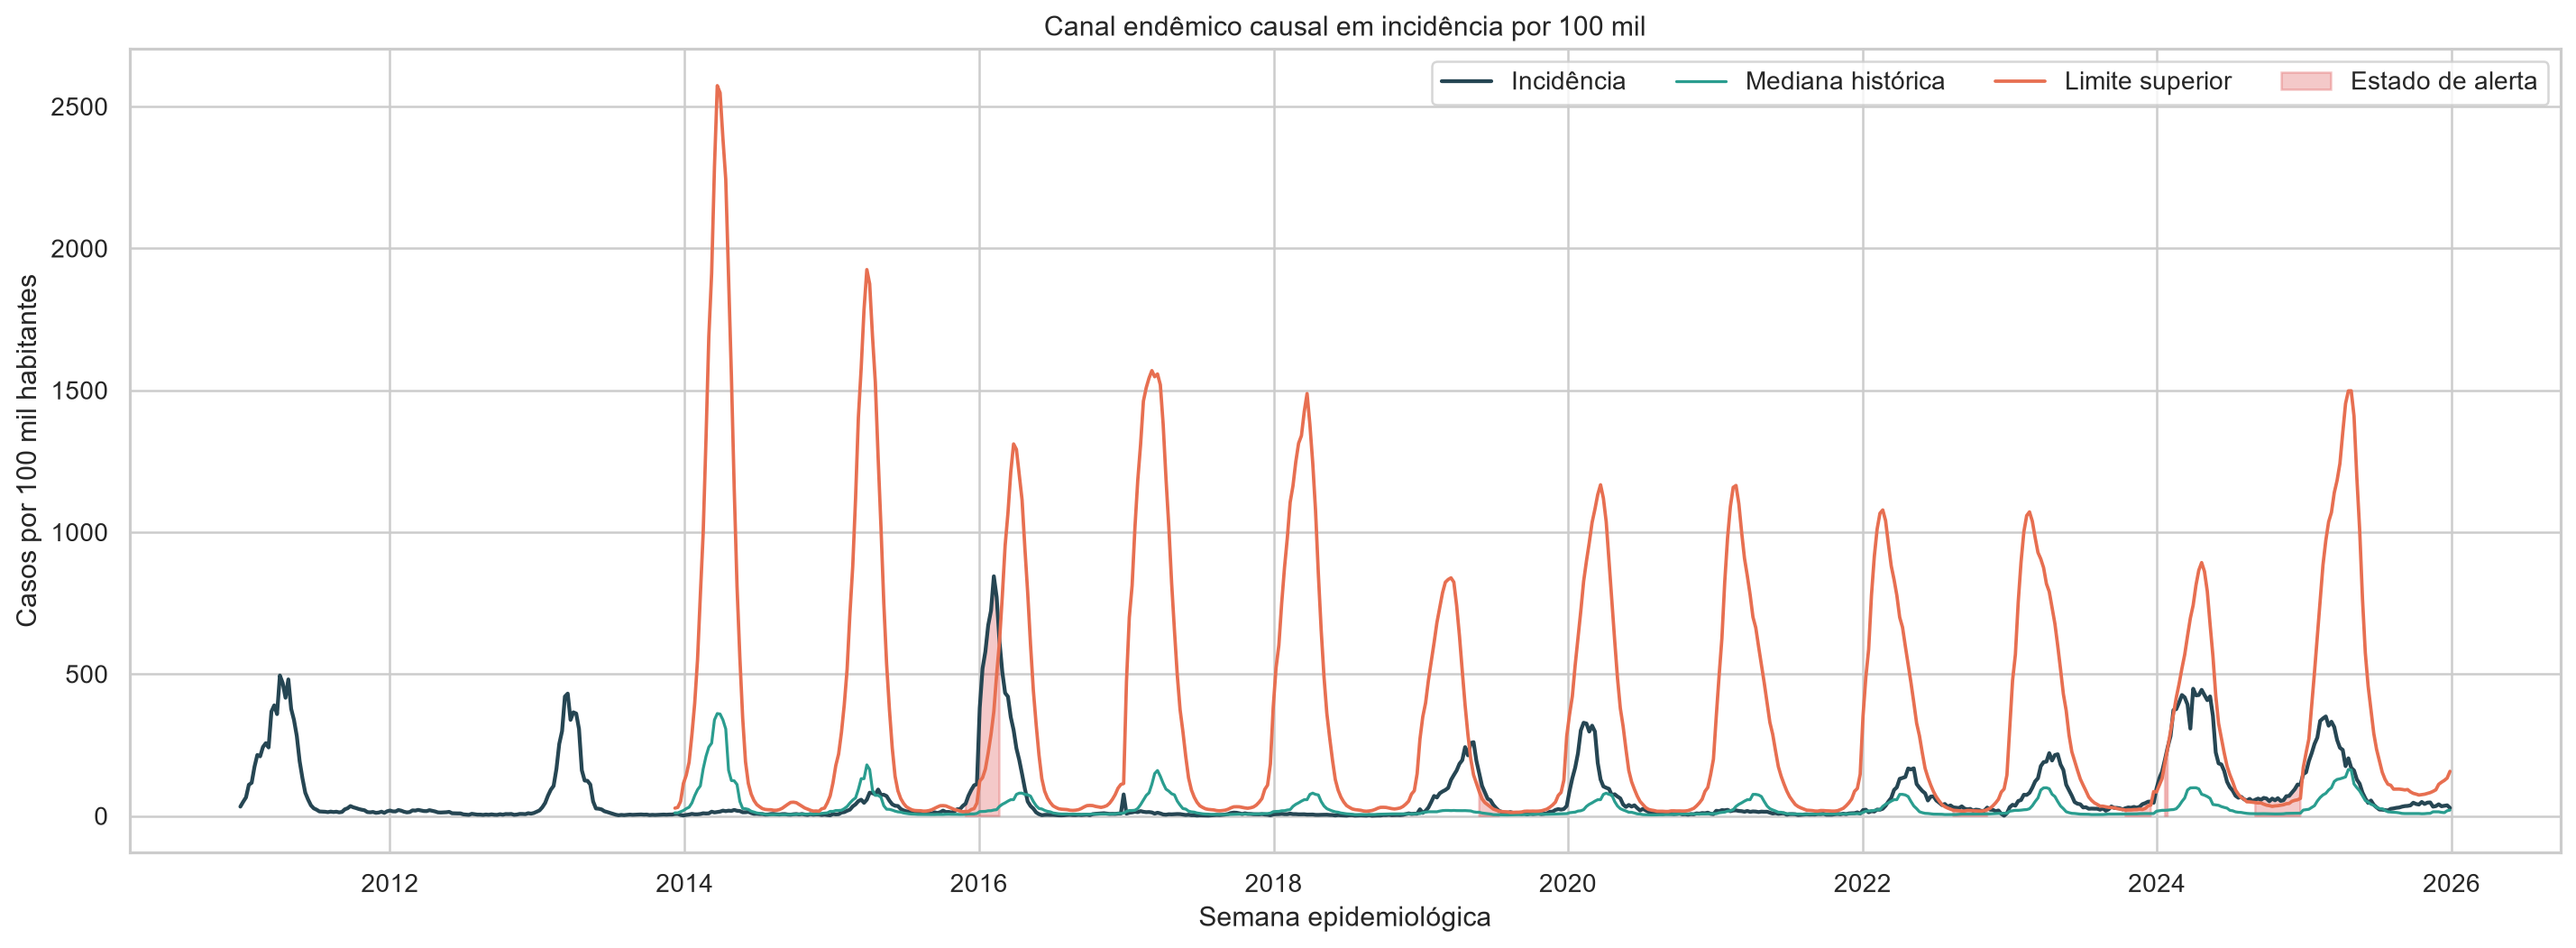

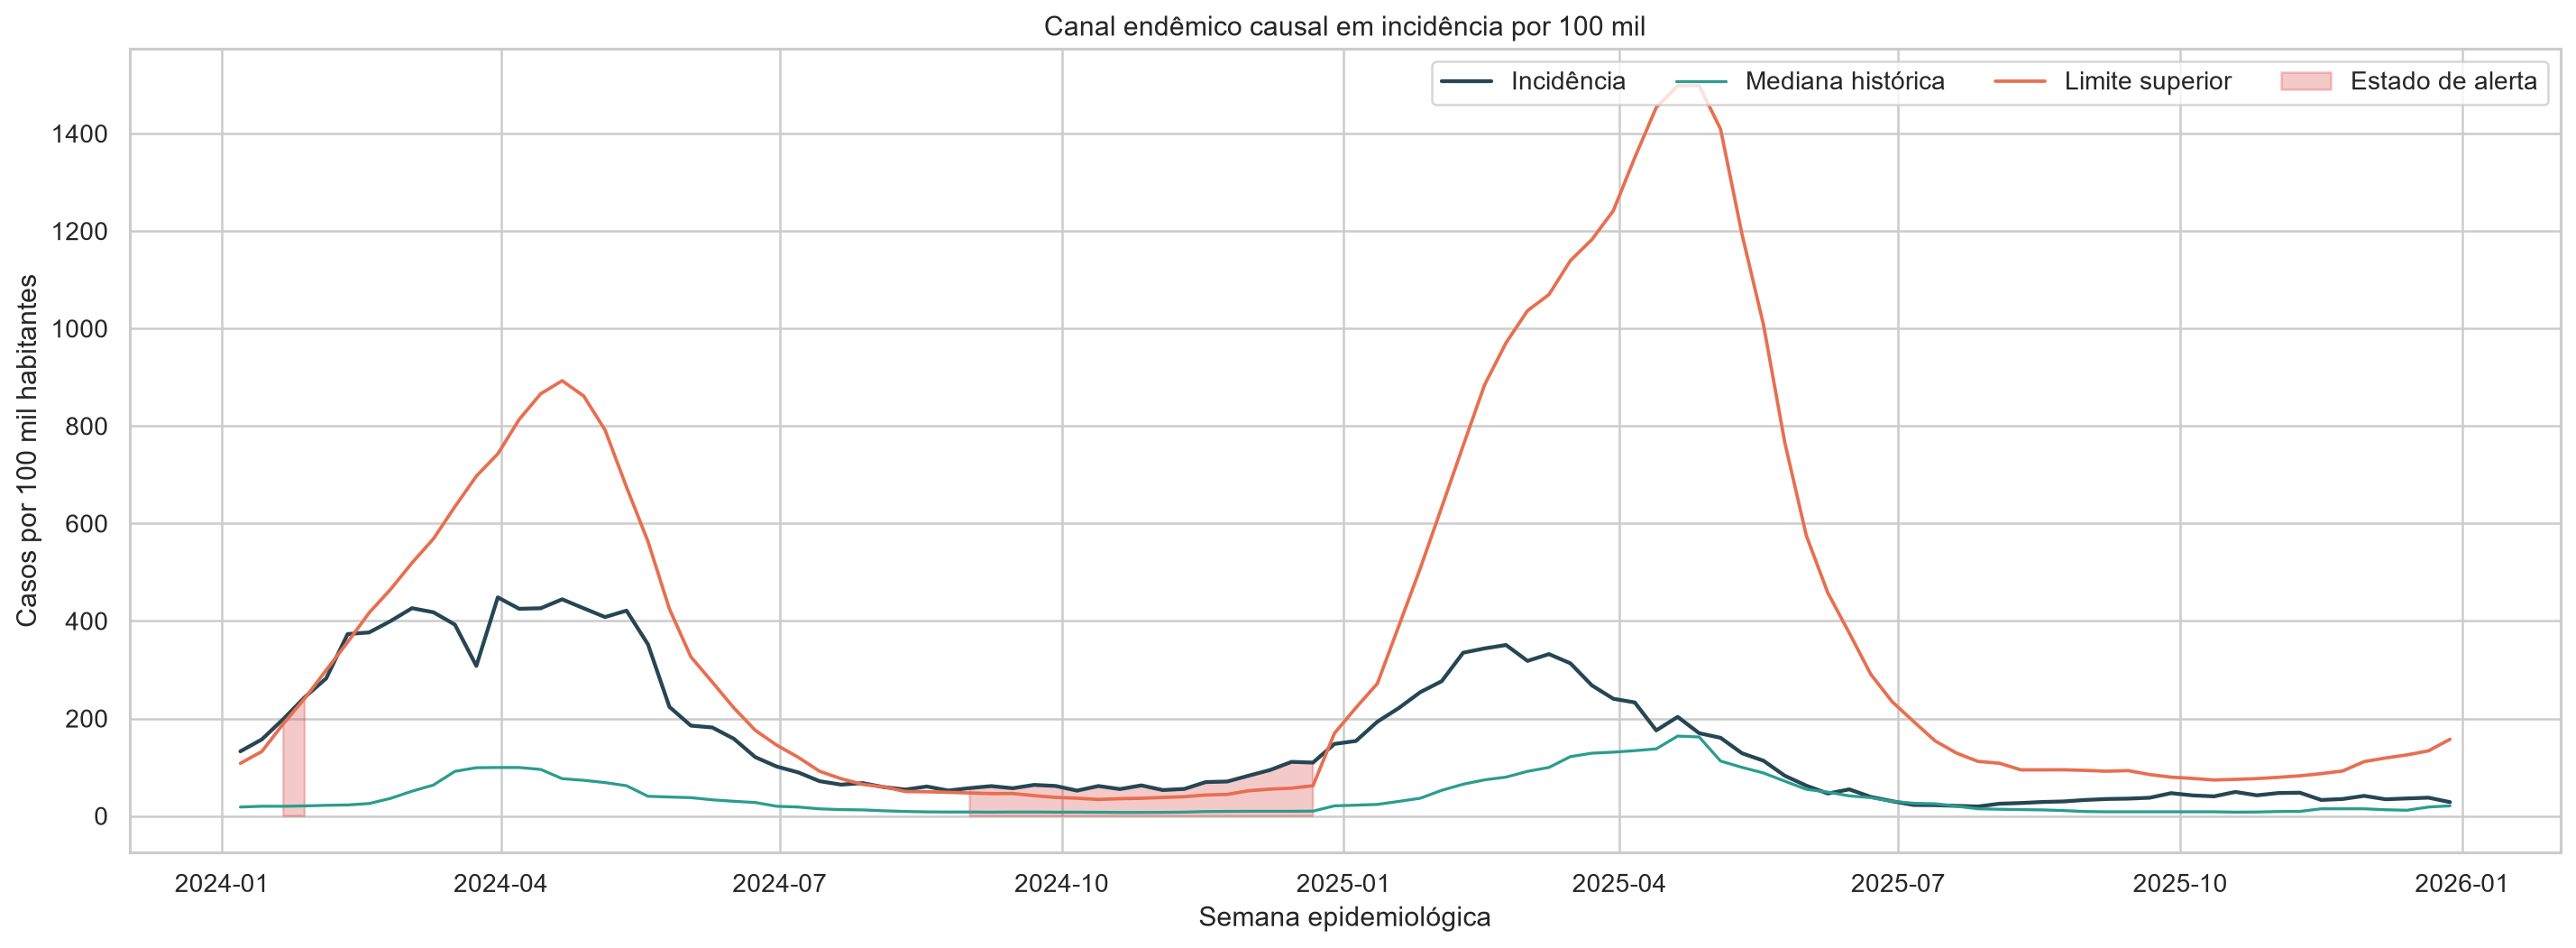

In [3]:
display(episodes)
display(Image(filename=str(OUTPUT_DIR / 'figuras/canal_endemico_completo.png')))
display(Image(filename=str(OUTPUT_DIR / 'figuras/canal_endemico_teste_2024_2025.png')))

## 3. Partições temporais

A partição é feita pela **data-alvo**, não pela data de emissão. Isso impede que uma previsão emitida no fim do treino tenha desfecho localizado na validação ou no teste. Transformações são ajustadas somente no treino; validação escolhe hiperparâmetros, early stopping e limiar; teste é usado uma vez.

In [4]:
display(splits[splits.target_kind.eq('exact')][['horizon','split','n','positive','prevalence','first_target_date','last_target_date']])

,horizon,split,n,positive,prevalence,first_target_date,last_target_date
0,4,train,417,21,0.050360,2014-01-05,2021-12-26
1,4,validation,105,23,0.219048,2022-01-02,2023-12-31
2,4,test,104,19,0.182692,2024-01-07,2025-12-28
3,8,train,413,21,0.050847,2014-02-02,2021-12-26
4,8,validation,105,23,0.219048,2022-01-02,2023-12-31
5,8,test,104,19,0.182692,2024-01-07,2025-12-28
6,12,train,409,21,0.051345,2014-03-02,2021-12-26
7,12,validation,105,23,0.219048,2022-01-02,2023-12-31
8,12,test,104,19,0.182692,2024-01-07,2025-12-28
9,16,train,405,21,0.051852,2014-03-30,2021-12-26


## 4. Modelos e resultado semanal

São comparados baseline sazonal, baseline de persistência, regressão logística, Random Forest, LSTM NumPy com BPTT completo e LSTM PyTorch. PR-AUC é a métrica principal de discriminação; o limiar é escolhido na validação visando recall ≥0,80 e maior precisão. Recall, especificidade, Brier e alarmes falsos descrevem o comportamento operacional.

,horizon,model_label,prevalence,pr_auc,roc_auc,precision,recall_sensitivity,specificity,f2,brier,false_alarms_per_year
7,4,Baseline persistência,0.183,0.462,0.789,0.183,1.000,0.000,0.528,0.144,42.645
9,4,LSTM NumPy (BPTT),0.183,0.342,0.620,0.258,0.421,0.729,0.374,0.280,11.539
3,4,Random Forest,0.183,0.264,0.681,0.276,0.421,0.753,0.381,0.159,10.536
1,4,Regressão logística,0.183,0.248,0.668,0.188,0.316,0.694,0.278,0.211,13.044
5,4,Baseline sazonal,0.183,0.172,0.454,0.183,1.000,0.000,0.528,0.174,42.645
11,4,LSTM PyTorch,0.183,0.135,0.321,0.175,0.737,0.224,0.449,0.280,33.113
19,8,Baseline persistência,0.183,0.289,0.669,0.183,1.000,0.000,0.528,0.240,42.645
13,8,Regressão logística,0.183,0.266,0.637,0.071,0.105,0.694,0.096,0.209,13.044
21,8,LSTM NumPy (BPTT),0.183,0.215,0.551,0.200,0.474,0.576,0.372,0.277,18.061
17,8,Baseline sazonal,0.183,0.178,0.464,0.183,1.000,0.000,0.528,0.174,42.645


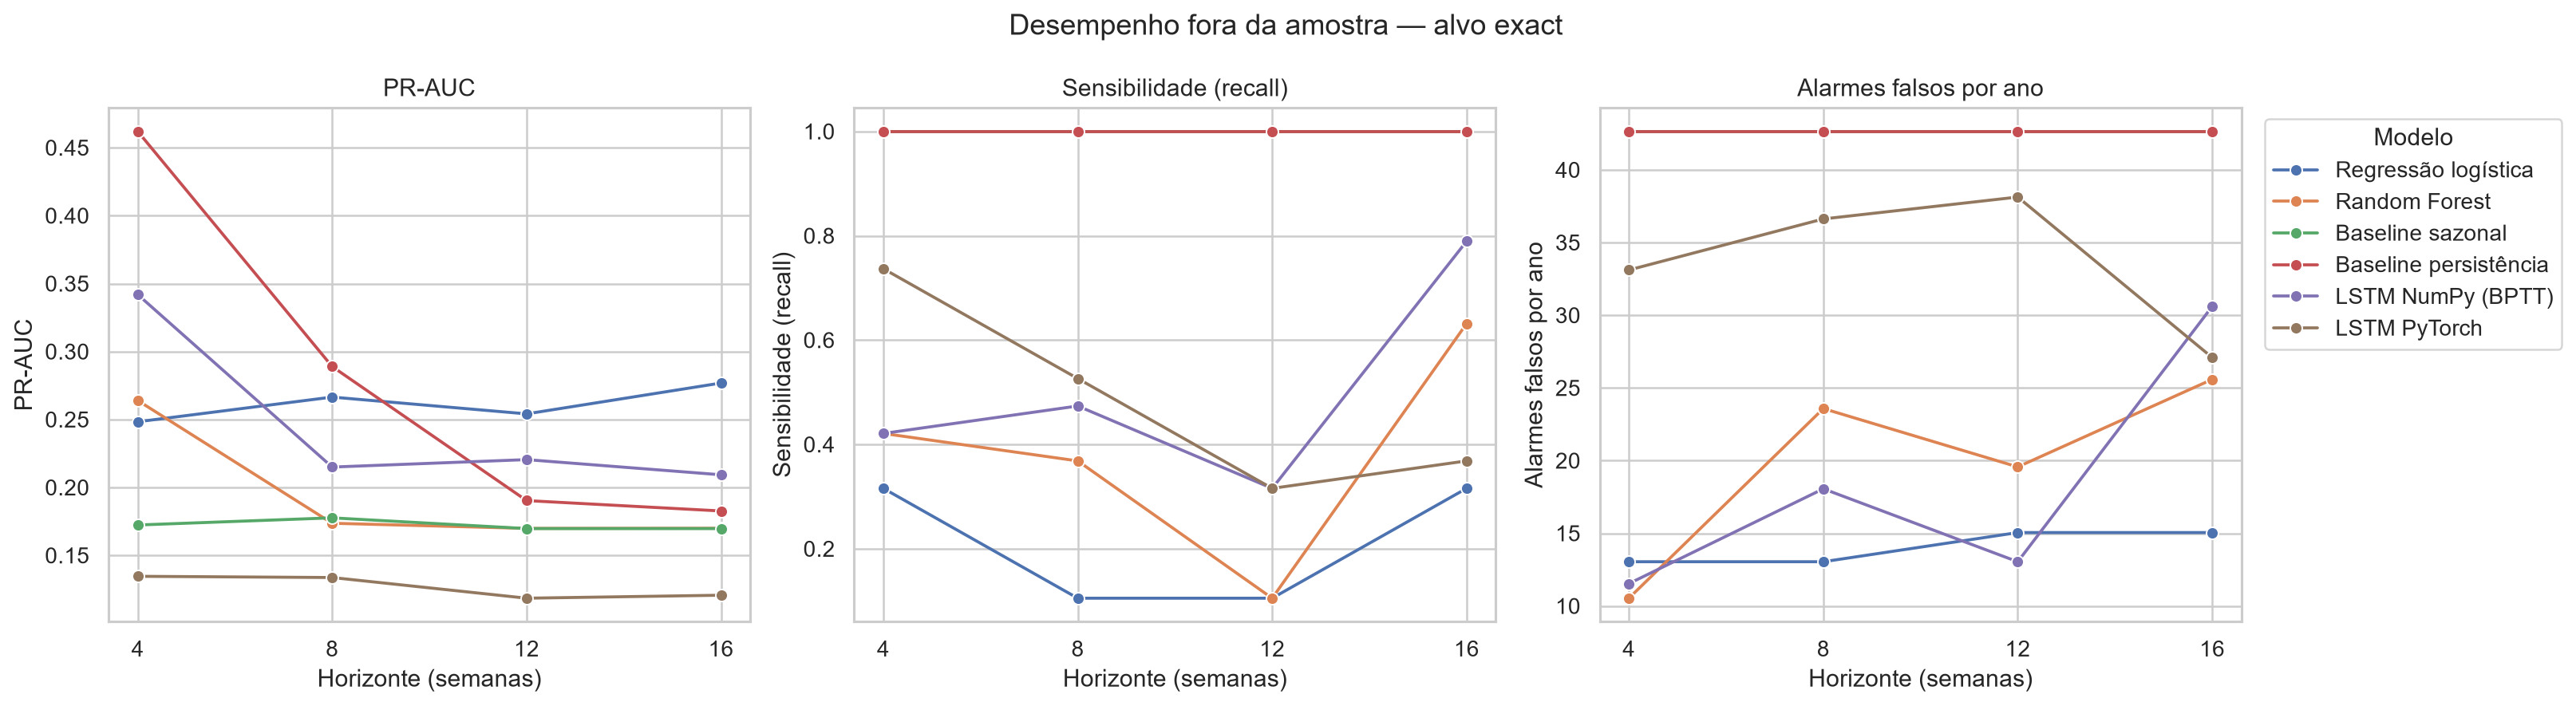

In [5]:
exact_test = metrics[(metrics.target_kind == 'exact') & (metrics.split == 'test')]
columns = ['horizon','model_label','prevalence','pr_auc','roc_auc','precision','recall_sensitivity','specificity','f2','brier','false_alarms_per_year']
display(exact_test[columns].sort_values(['horizon','pr_auc'], ascending=[True,False]).round(3))
display(Image(filename=str(OUTPUT_DIR / 'figuras/comparacao_exact.png')))

### Interpretação central

O desempenho elevado da definição P75 anterior não se reproduz com o alerta epidemiológico mais estrito. No teste, a prevalência é cerca de 18%, o LSTM PyTorch apresenta PR-AUC inferior à prevalência em todos os horizontes e modelos simples são mais competitivos. Os baselines que obtêm recall 1 classificam praticamente todas as semanas como positivas no limiar selecionado e, portanto, não são operacionalmente úteis.

Esse resultado negativo não deve ser ocultado nem “corrigido” escolhendo uma nova definição após observar o teste. Ele indica forte dependência do construto e amostra insuficiente para sustentar a LSTM como modelo principal.

## 5. Início de episódios e antecedência

Um episódio é detectado se houver ao menos um aviso entre `início-h` e `início-1`. Como existem somente dois inícios no teste, recall de episódio assume apenas 0, 0,5 ou 1; alarmes falsos e validação prospectiva são indispensáveis para interpretação.

In [6]:
display(event_metrics[['horizon','model_label','n_test_episodes','episodes_detected','episode_recall','median_maximum_lead_weeks','false_warning_weeks_per_year']].sort_values(['horizon','episode_recall','false_warning_weeks_per_year'], ascending=[True,False,True]).round(3))

,horizon,model_label,n_test_episodes,episodes_detected,episode_recall,median_maximum_lead_weeks,false_warning_weeks_per_year
2,4,Baseline sazonal,2,2,1.0,4.0,48.164
3,4,Baseline persistência,2,2,1.0,4.0,48.164
4,4,LSTM NumPy (BPTT),2,1,0.5,4.0,7.526
0,4,Regressão logística,2,1,0.5,4.0,10.034
1,4,Random Forest,2,1,0.5,4.0,20.570
5,4,LSTM PyTorch,2,1,0.5,4.0,33.614
11,8,LSTM PyTorch,2,2,1.0,8.0,30.604
8,8,Baseline sazonal,2,2,1.0,8.0,44.150
9,8,Baseline persistência,2,2,1.0,8.0,44.150
6,8,Regressão logística,2,1,0.5,8.0,10.536


## 6. Sensibilidade do desfecho

Vinte e quatro especificações variam janela histórica, raio de semanas, limite superior e persistência. Essa análise mede incerteza da definição, mas não autoriza escolher retrospectivamente o rótulo que maximiza o desempenho.

,lookback_years,week_radius,upper_method,persistence_weeks,alert_weeks,episodes,jaccard_vs_primary,train_alert_weeks,validation_alert_weeks,test_alert_weeks,is_primary
2,5,1,p90,3,130,6,0.485,33,42,55,False
3,5,1,p90,4,124,6,0.508,30,39,55,False
8,5,2,p90,3,123,5,0.512,30,41,52,False
14,7,1,p90,3,121,5,0.521,31,34,56,False
20,7,2,p90,3,120,5,0.525,30,35,55,False
9,5,2,p90,4,118,5,0.534,28,38,52,False
4,5,1,p95,3,115,6,0.534,28,37,50,False
15,7,1,p90,4,116,5,0.543,28,32,56,False
10,5,2,p95,3,110,6,0.545,29,36,45,False
21,7,2,p90,4,115,4,0.548,27,33,55,False


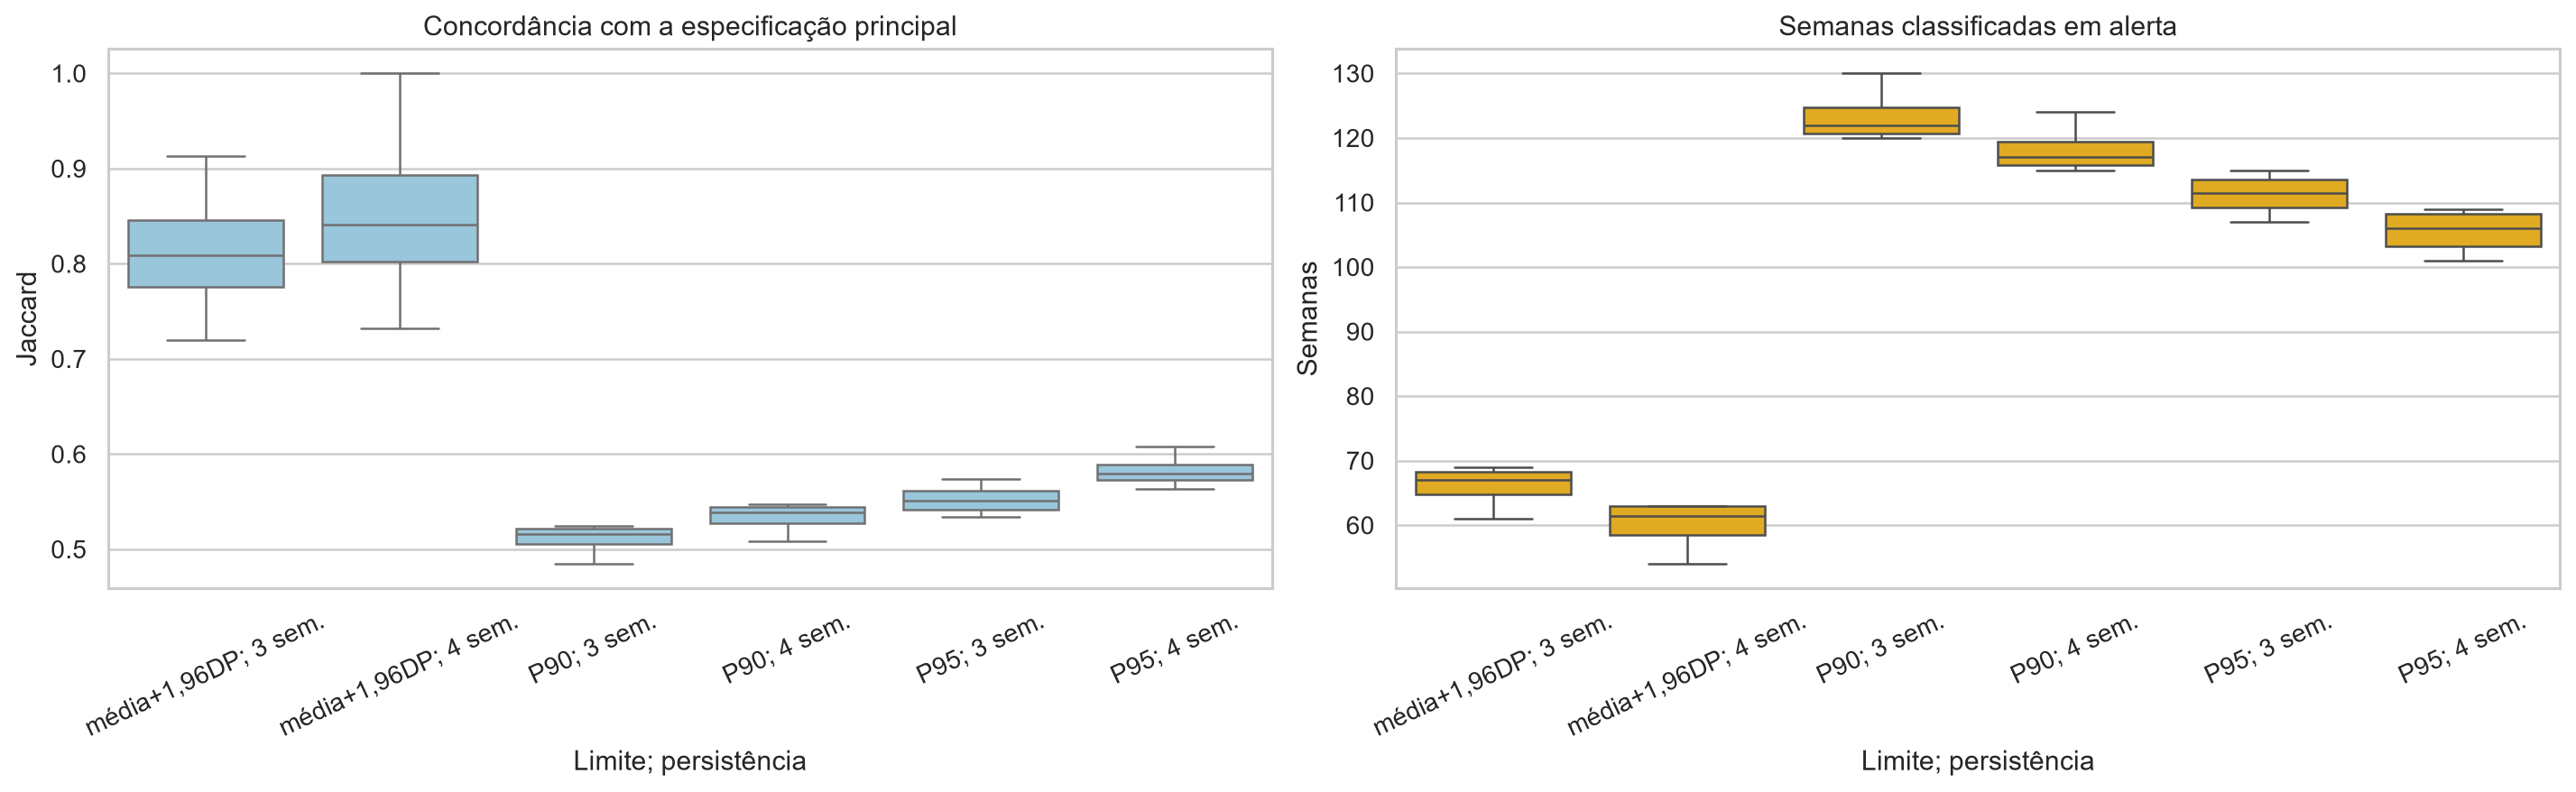

In [7]:
display(sensitivity.sort_values('jaccard_vs_primary').round(3))
display(Image(filename=str(OUTPUT_DIR / 'figuras/sensibilidade_definicao.png')))

## 7. Captum no LSTM PyTorch

Integrated Gradients e Occlusion usam apenas amostras de teste. O baseline zero no espaço padronizado corresponde à média do treino. As atribuições explicam logits do modelo e não causalidade epidemiológica.

### Horizonte: 4 semanas

,feature,mean_absolute_attribution,mean_signed_attribution
0,incidence_mean_4,0.01125,0.01077
1,media_umidade_semana,0.00998,-0.00311
2,log_incidence_lag_52,0.00878,-0.00850
3,incidence_ratio_upper_lag1,0.00837,0.00737
4,ONI,0.00665,0.00027
5,incidence_mean_12,0.00634,0.00603
6,chuva_total_mm,0.00579,-0.00056
7,log_incidence_lag_4,0.00566,0.00566


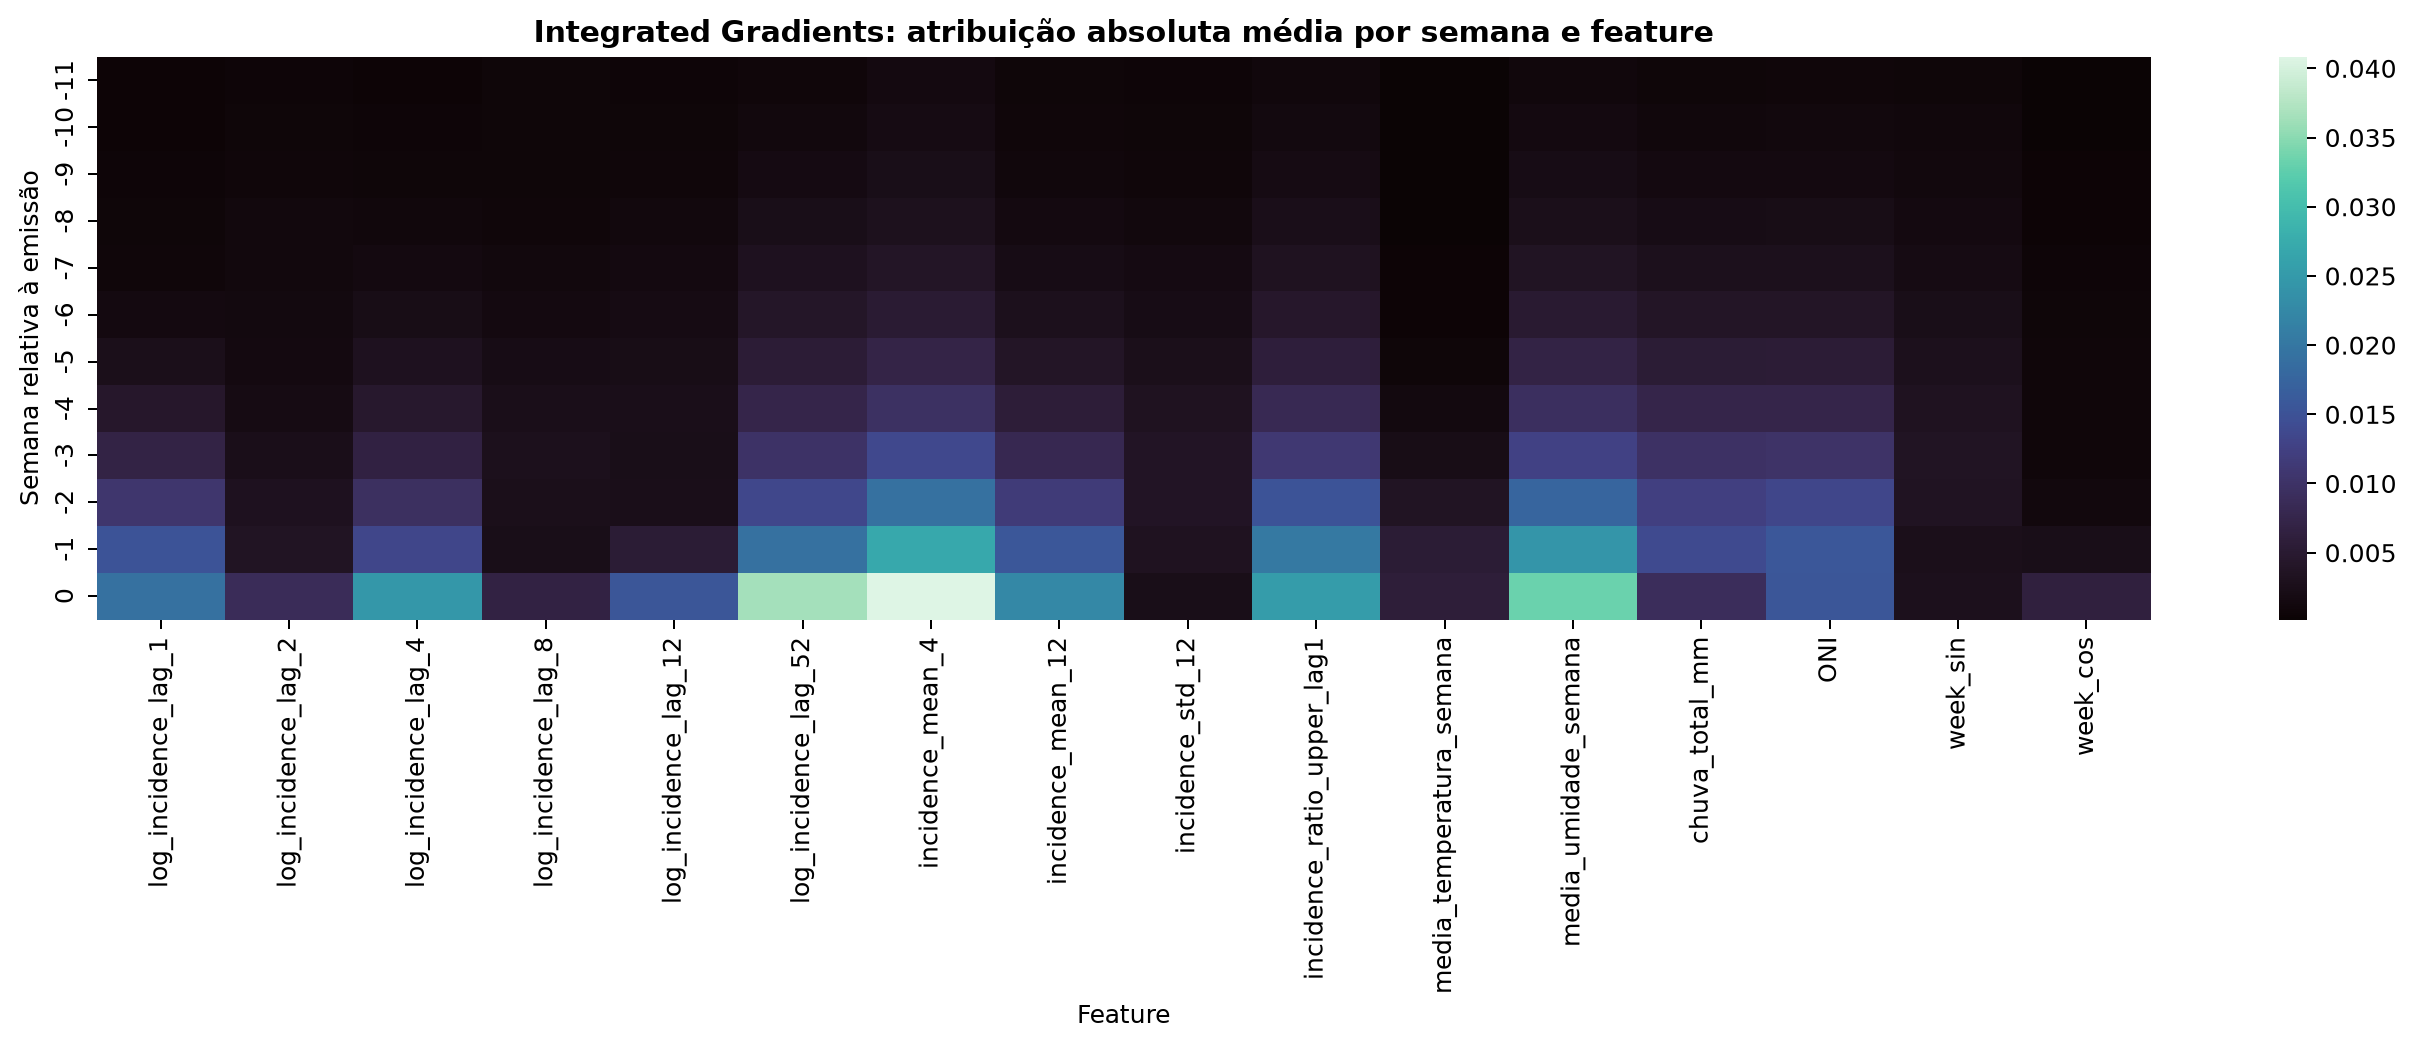

### Horizonte: 8 semanas

,feature,mean_absolute_attribution,mean_signed_attribution
0,incidence_mean_4,0.00582,0.00549
1,media_umidade_semana,0.00524,-0.00151
2,ONI,0.00432,0.00062
3,chuva_total_mm,0.00384,-0.00029
4,log_incidence_lag_52,0.00361,-0.00348
5,incidence_ratio_upper_lag1,0.00335,0.00301
6,log_incidence_lag_8,0.00304,-0.00302
7,incidence_std_12,0.00286,-0.00206


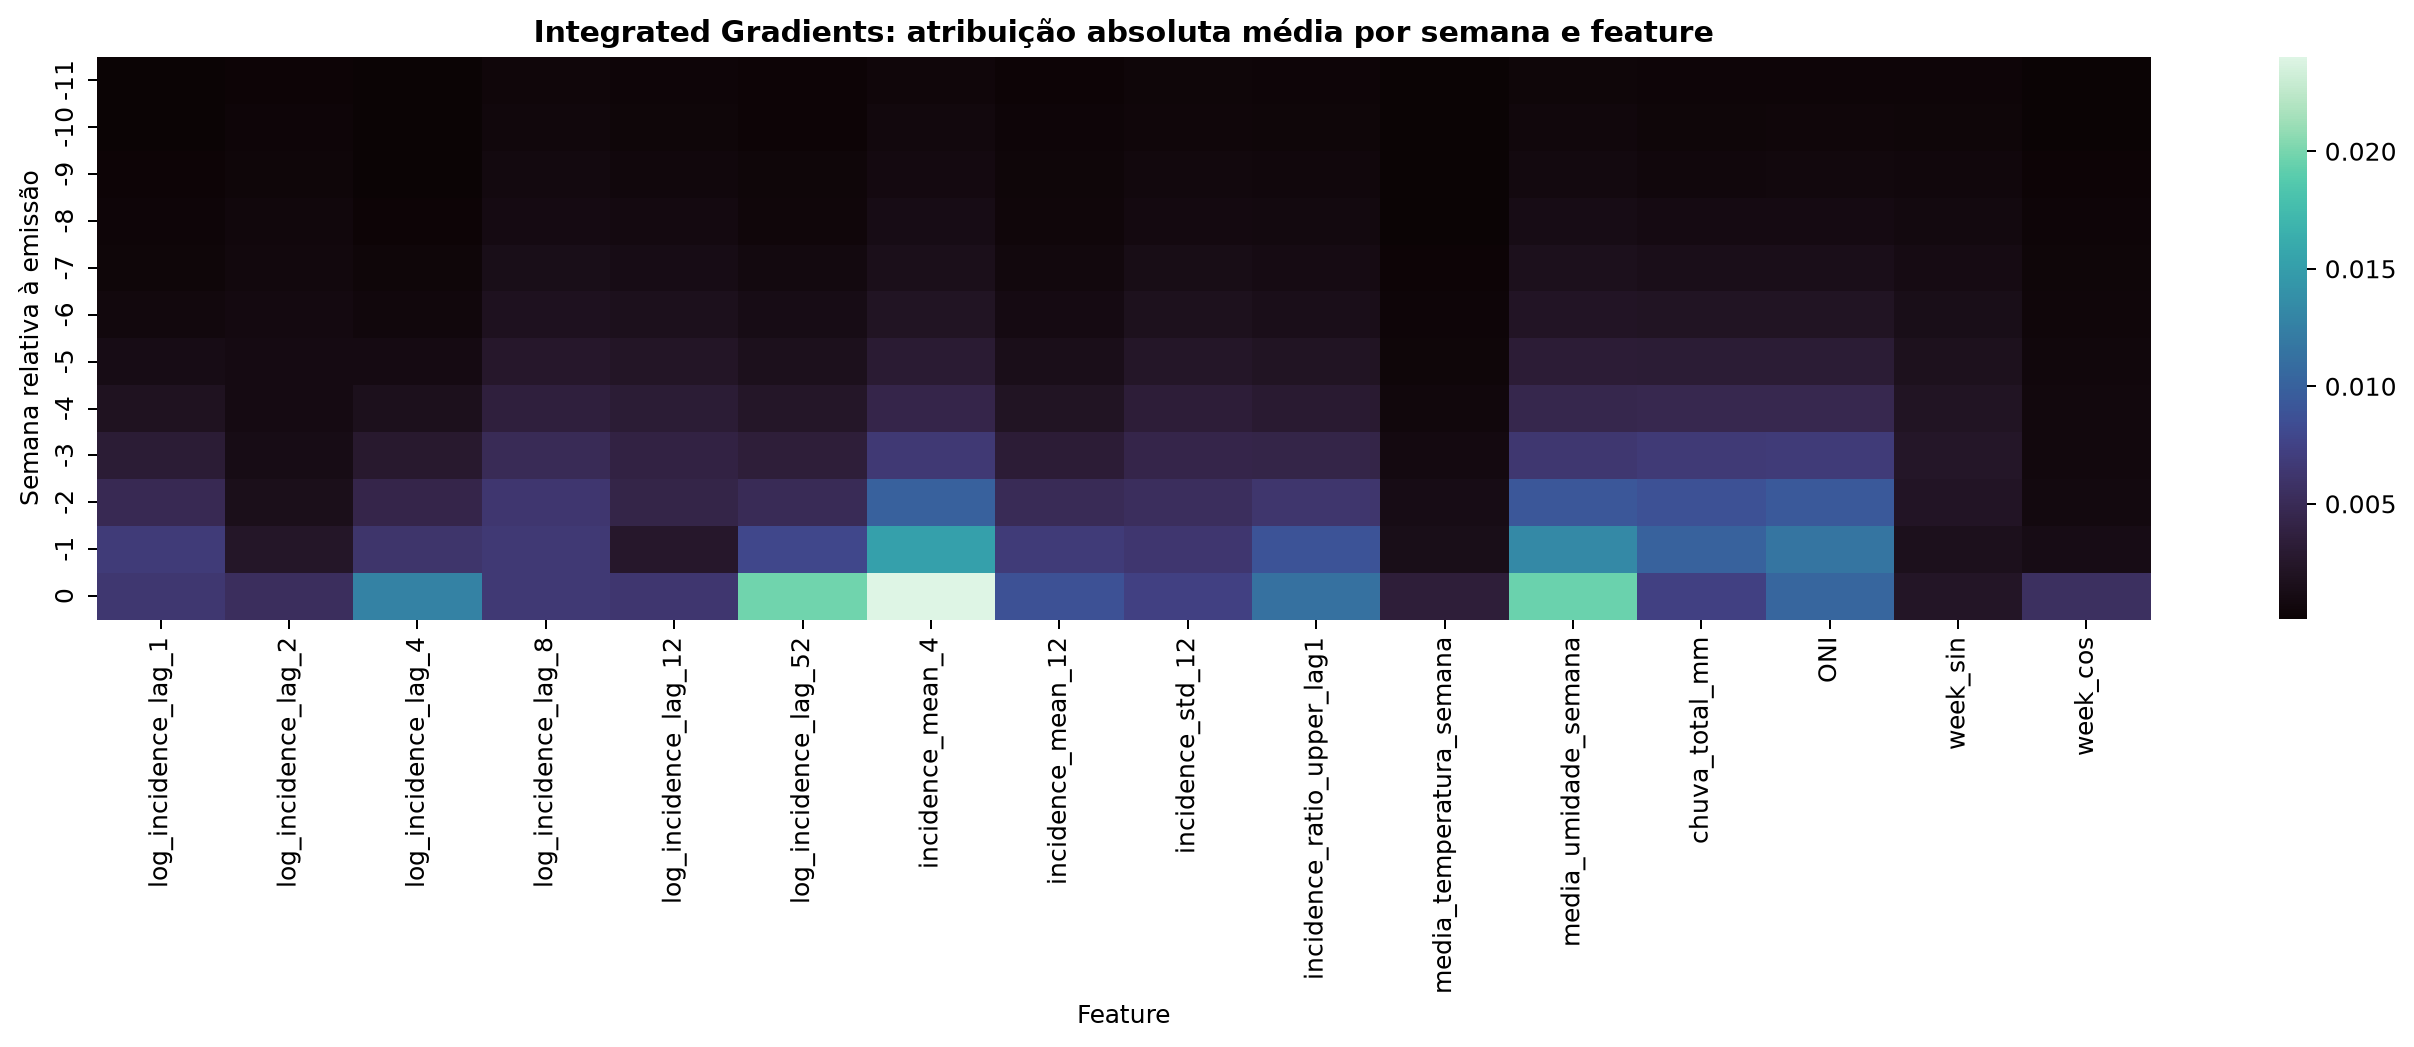

### Horizonte: 12 semanas

,feature,mean_absolute_attribution,mean_signed_attribution
0,log_incidence_lag_8,0.00456,-0.00456
1,media_umidade_semana,0.00374,-0.00071
2,incidence_mean_4,0.00374,0.00353
3,chuva_total_mm,0.00237,0.00011
4,incidence_std_12,0.00215,-0.00148
5,log_incidence_lag_12,0.00190,-0.00152
6,ONI,0.00190,0.00046
7,week_sin,0.00160,0.00060


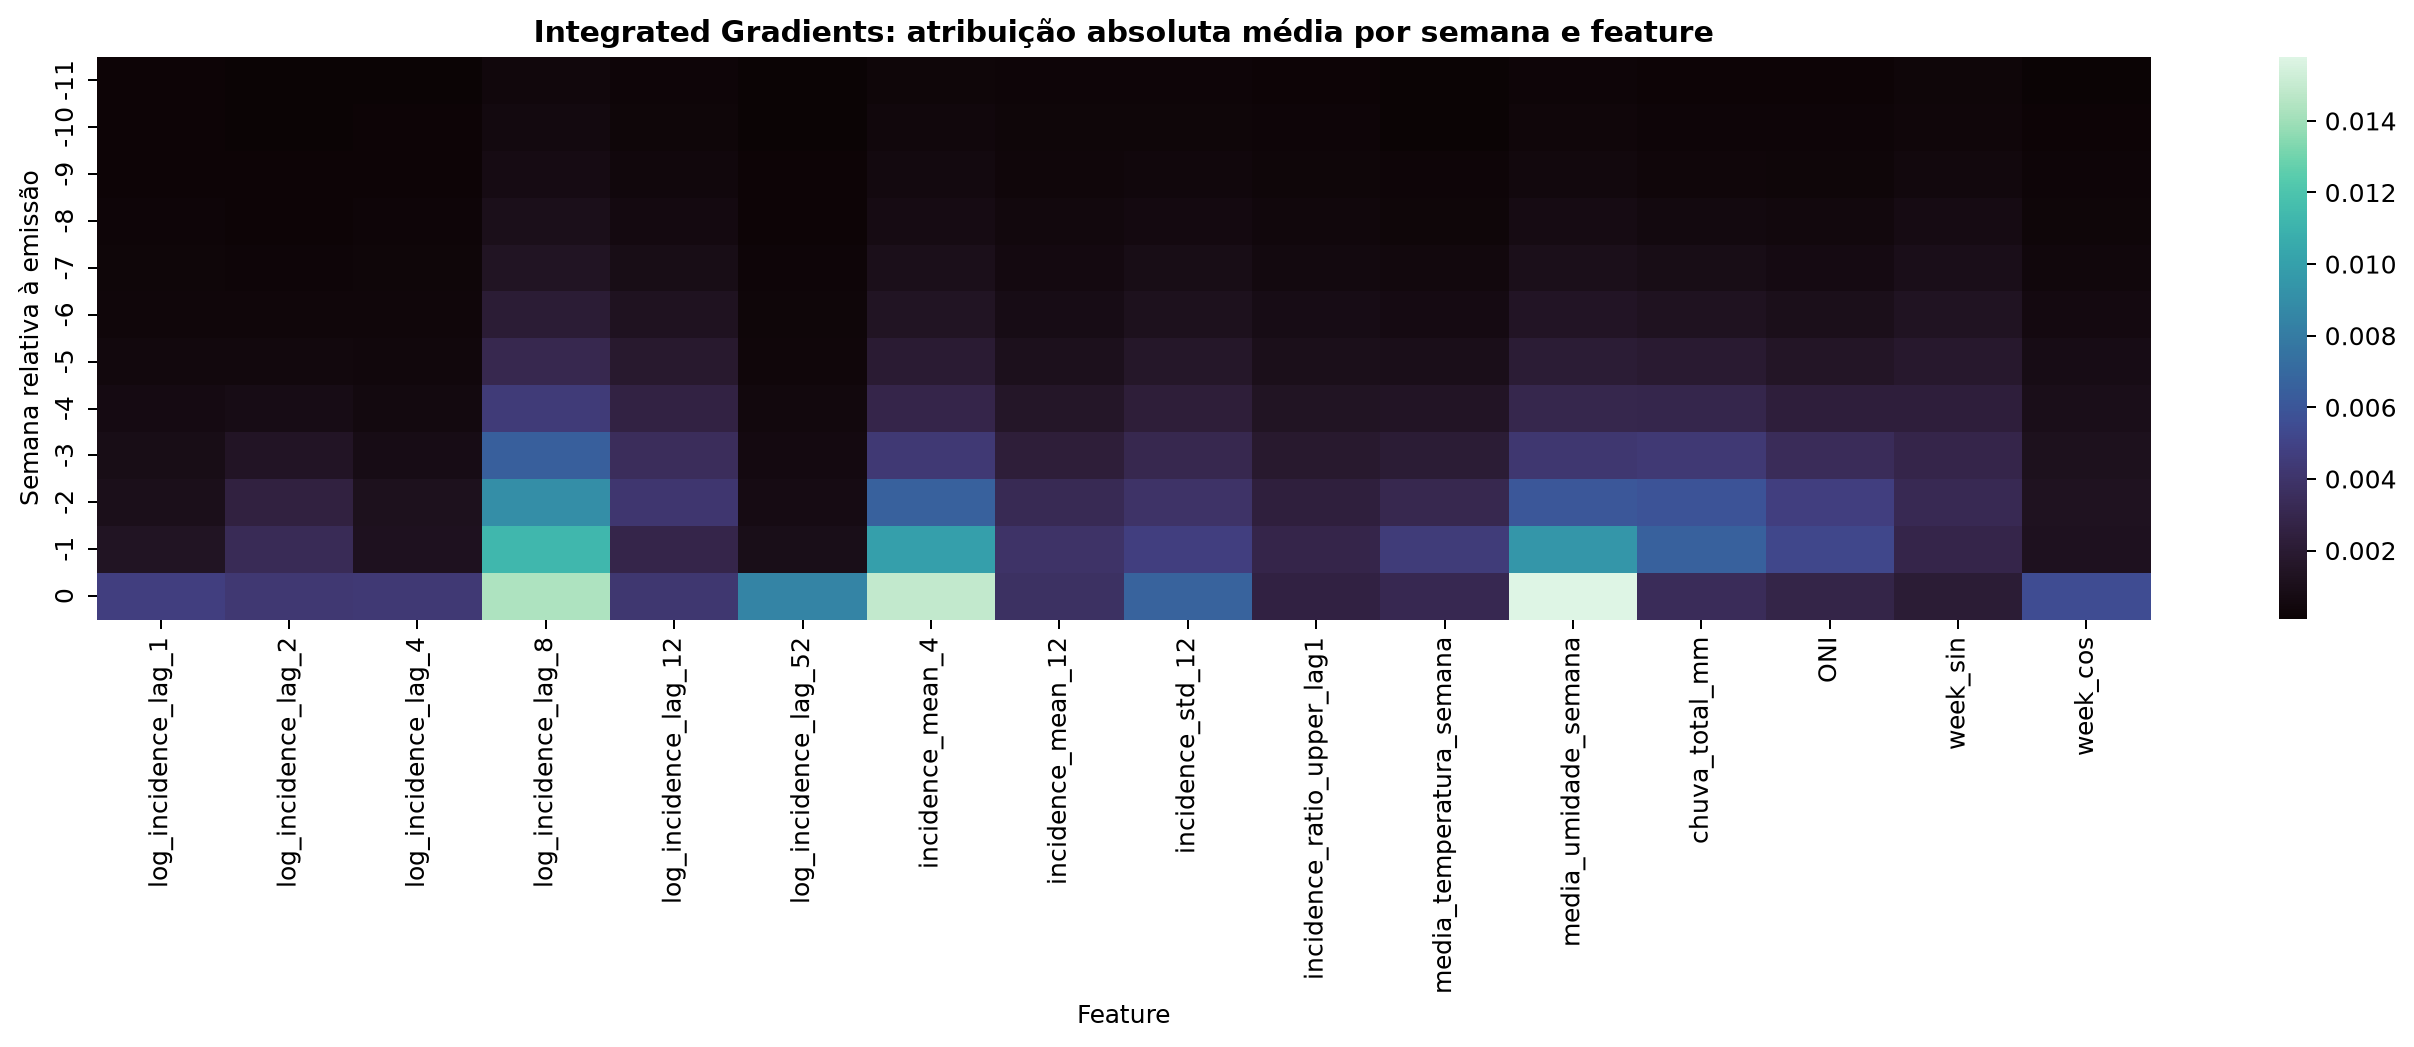

### Horizonte: 16 semanas

,feature,mean_absolute_attribution,mean_signed_attribution
0,log_incidence_lag_8,0.00489,-0.00489
1,incidence_mean_4,0.00298,0.00281
2,media_umidade_semana,0.00266,-0.00036
3,incidence_std_12,0.00240,-0.00161
4,ONI,0.00229,0.00068
5,chuva_total_mm,0.00182,0.00013
6,log_incidence_lag_2,0.00181,-0.00169
7,media_temperatura_semana,0.00166,-0.00043


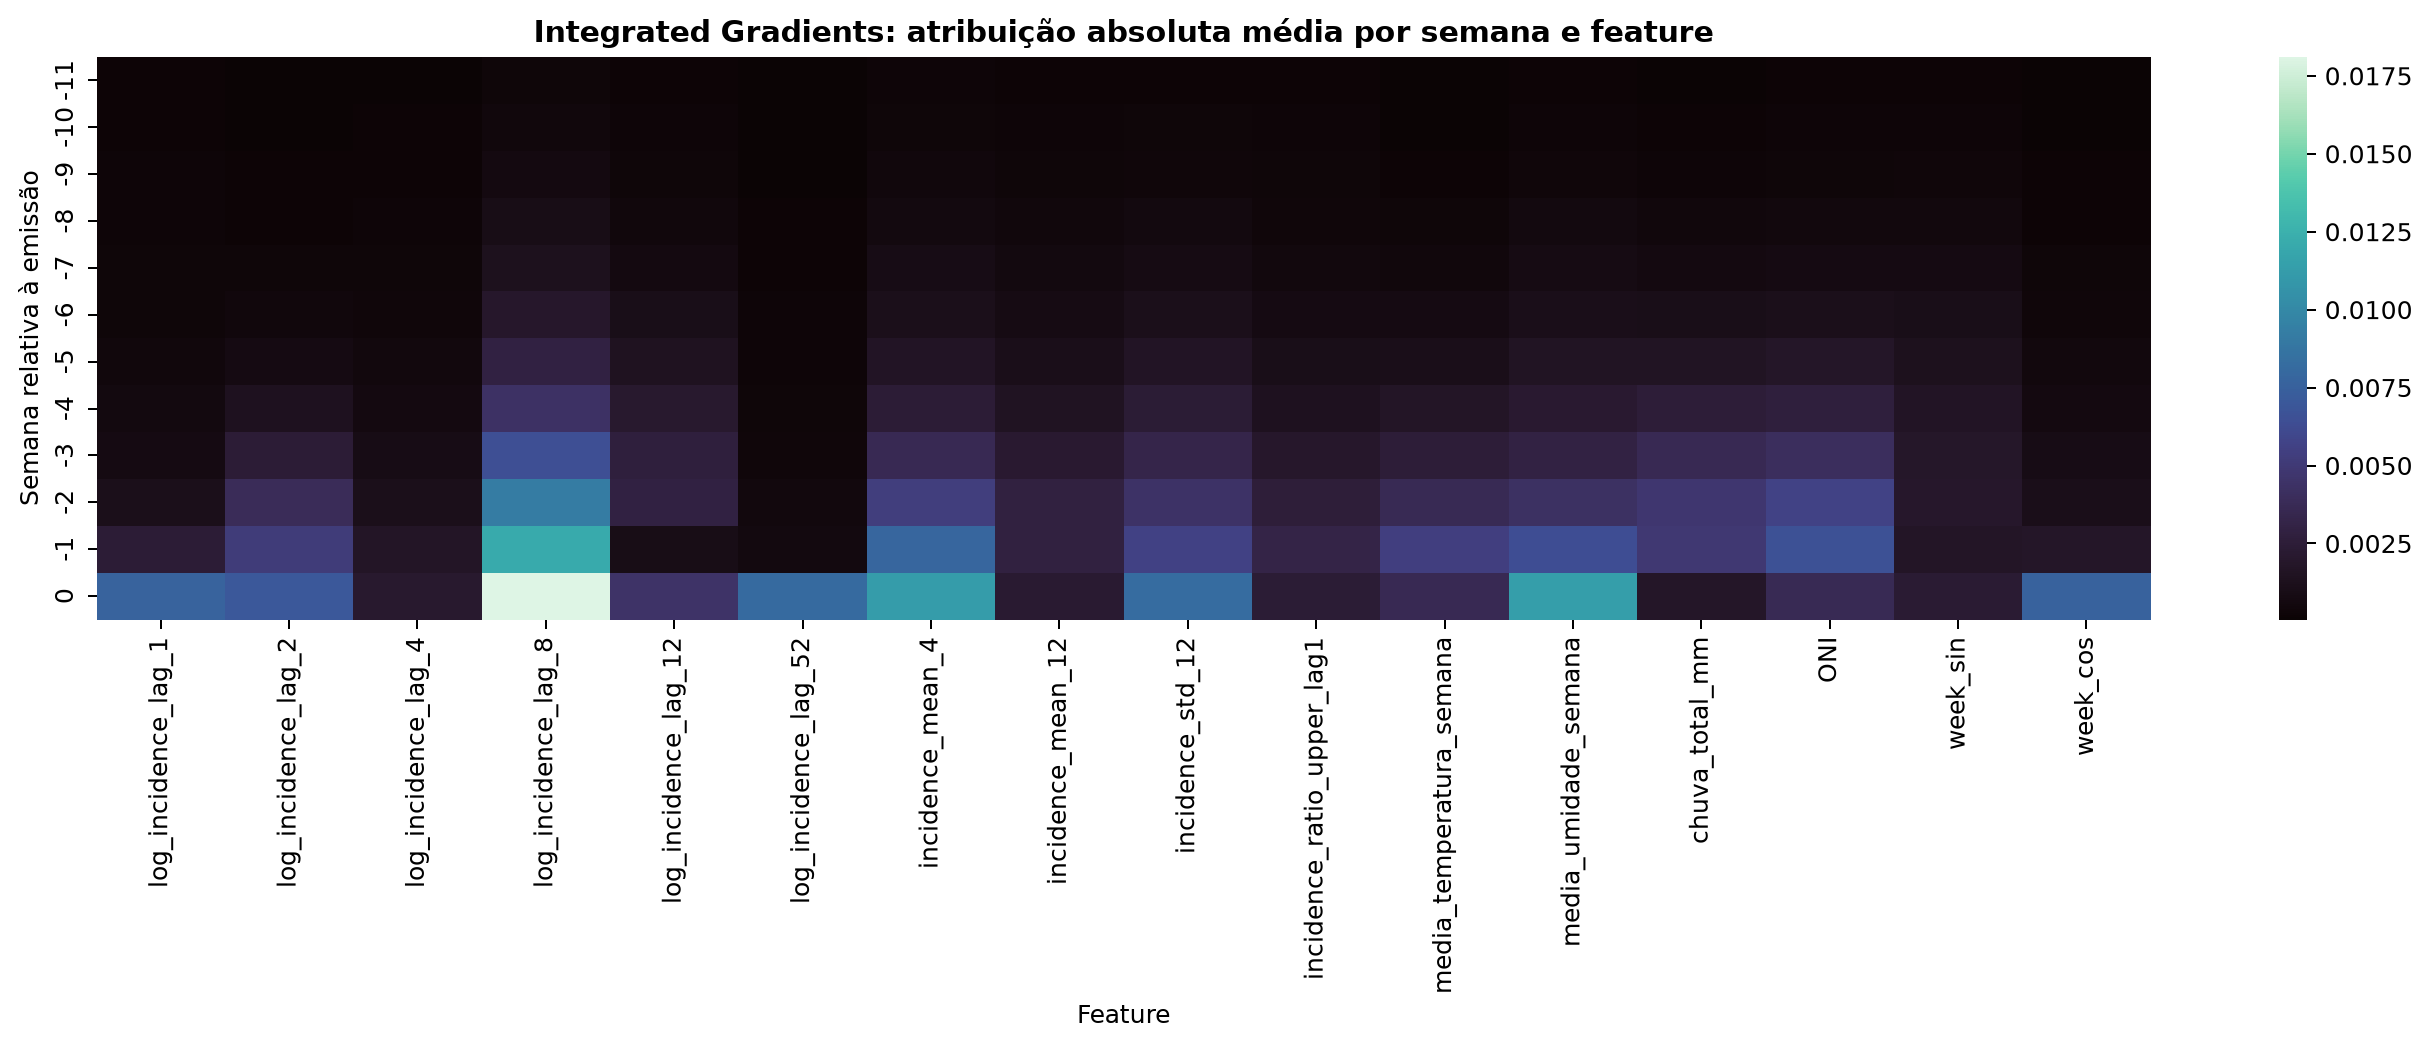

In [8]:
for horizon in (4,8,12,16):
    path = OUTPUT_DIR / f'exact/{horizon:02d}_semanas/captum/integrated_gradients_features.csv'
    top = pd.read_csv(path).head(8)
    display(Markdown(f'### Horizonte: {horizon} semanas'))
    display(top.round(5))
    display(Image(filename=str(OUTPUT_DIR / f'exact/{horizon:02d}_semanas/captum/integrated_gradients_heatmap.png')))

## 8. Comparação com a versão anterior

A comparação é descritiva porque os rótulos representam construtos diferentes. Concordância alta entre semanas negativas pode coexistir com baixa concordância entre semanas positivas; por isso, Jaccard e prevalência são apresentados junto às métricas.

In [9]:
comparison_path = PROJECT_ROOT / 'reports/comparacao_definicoes.md'
display(Markdown(comparison_path.read_text(encoding='utf-8')))

# Comparação entre as duas definições de desfecho

## Leitura correta da comparação

As duas versões não diferem apenas em código: elas medem construtos distintos. A versão anterior usa contagens e um P75 causal com persistência de três semanas. A versão epidemiológica usa incidência por 100 mil, limite superior em escala logarítmica e quatro semanas consecutivas. Assim, diferenças de desempenho não devem ser interpretadas como uma competição direta entre modelos sobre o mesmo problema.

## Concordância dos rótulos semanais

- Semanas válidas comparadas: 630.
- Concordância bruta: 0.724.
- Jaccard entre semanas positivas: 0.266.
- Positivos na definição anterior: 237; positivos na nova definição: 63.

## Melhor PR-AUC por horizonte em cada definição

| definition | horizon | model_label | prevalence | pr_auc | precision | recall_sensitivity | false_alarms_per_year |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Incidência/canal oficial-alinhado | 4 | Baseline persistência | 0.183 | 0.462 | 0.183 | 1.000 | 42.645 |
| P75 causal anterior | 4 | Regressão logística | 0.644 | 0.962 | 0.980 | 0.731 | 0.502 |
| Incidência/canal oficial-alinhado | 8 | Baseline persistência | 0.183 | 0.289 | 0.183 | 1.000 | 42.645 |
| P75 causal anterior | 8 | LSTM PyTorch | 0.644 | 0.927 | 0.652 | 0.896 | 16.055 |
| Incidência/canal oficial-alinhado | 12 | Regressão logística | 0.183 | 0.254 | 0.062 | 0.105 | 15.051 |
| P75 causal anterior | 12 | LSTM PyTorch | 0.644 | 0.927 | 0.644 | 1.000 | 18.563 |
| Incidência/canal oficial-alinhado | 16 | Regressão logística | 0.183 | 0.277 | 0.167 | 0.316 | 15.051 |
| P75 causal anterior | 16 | LSTM PyTorch | 0.644 | 0.901 | 0.644 | 1.000 | 18.563 |

## Conclusão comparativa

A especificação epidemiológica é mais defensável como desfecho primário porque normaliza por população, separa estado de alerta de início de episódio e ancora os parâmetros em orientações sanitárias. A versão P75 permanece útil como análise de sensibilidade histórica. Métricas de uma versão não validam a outra, e a estabilidade da conclusão deve ser julgada pela concordância da ordenação dos modelos, pelas curvas fora da amostra e pelo desempenho por episódio.


## 9. Limitações decisivas

- seis episódios totais e apenas dois em cada partição principal;
- ausência de rótulo oficial independente de surto/epidemia;
- `dem` sem proveniência formal confirmada;
- uma única série municipal;
- latência de notificação e revisão de dados ainda não modeladas;
- clima e índices externos dependem da disponibilidade real na data de emissão;
- resultados de uma semente não quantificam instabilidade da LSTM.

O pipeline é adequado para uma análise de doutorado transparente, mas os resultados atuais **não sustentam implantação operacional** nem superioridade da LSTM. O próximo passo científico é validar o desfecho com vigilância epidemiológica, documentar as fontes, repetir sementes e realizar validação geográfica ou prospectiva.

## 10. Artefatos reproduzíveis

- execução: `scripts/run_epidemiological_study.py`;
- definição e avaliação: `src/dengue_research/epidemiology.py`;
- relatórios: `src/dengue_research/epidemiological_reporting.py`;
- resultados completos: `outputs/revisao_epidemiologica`;
- relatório detalhado: `reports/relatorio_definicao_epidemiologica.md`.